# Agricultural Yield Prediction — Linear, Polynomial (Ridge, Lasso) and Decision Tree Regression

**Target:** `yield_kg_ha`  |  **Data:** `final_1.csv`

This notebook is built from `Random_Forest_Regression_fixed (2).ipynb` (same sections, cleaning style, evaluation helper and comparison plots) and develops these algorithms:

| # | Model | Tuned hyperparameter |
|---|---|---|
| 1 | Linear Regression | none |
| 2 | Linear Regression + Ridge | `alpha` |
| 3 | Linear Regression + Lasso | `alpha` |
| 4 | Polynomial Regression (degree 2) | none |
| 5 | Polynomial Regression + Ridge | `alpha` |
| 6 | Polynomial Regression + Lasso | `alpha` |
| 7 | Decision Tree (untuned and tuned) | `max_depth`, `min_samples_leaf`, `min_samples_split` |

**Data-quality fixes applied before modelling** (found when reviewing the earlier notebooks):
1. Country labels are cleaned and merged into the 20 real countries; crop labels are merged too.
2. `-999` missing-value markers are replaced by missing values before missing rows are dropped.
3. `rainfall` and `precip_mm` are the same measurement, so only rows where they agree are kept and `precip_mm` is dropped.
4. Physically impossible values are removed (negative rainfall, soil moisture outside 0–1, `temp_max < temp_min`, wrong `temp_range`, impossible years).
5. Duplicates are removed **after** the labels are cleaned.
6. The split is **time-based** (train 1990–2014, validation 2015–2019, test 2020–2024), not random.
7. Outlier reference values come from the **training years only**.

**Modelling choices:**
- All models are trained on `log1p(yield)` using `TransformedTargetRegressor`; predictions are converted back, so all MAE, RMSE and R² values are in kg/ha.
- Linear models scale the numeric weather columns with `StandardScaler`. Polynomial features are made only from these 17 numeric columns (not from the crop and country dummy columns, which would create thousands of useless columns).
- Ridge and Lasso penalties are chosen with time-ordered cross-validation on the training years only. The test set is used only for the final evaluation.

## 1. Import libraries and load data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import difflib
import joblib

from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_style("whitegrid")

# Keep final_1.csv in the same folder as this notebook
df = pd.read_csv("final_1.csv", low_memory=False)

print("Shape:", df.shape)
display(df.head())

Shape: (54423, 31)


,Country,Crop,Year,Yield,Flag,temp,tmax,tmin,humidity,soil_root,...,rainfall,Unit,Note,Domain Code,Domain,Area Code (M49),Element Code,Element,Item Code (CPC),Flag Description
0,Türkiye,Sugar beet,1993,37052.1,A,15.203333333333331,40.22,-8.096666666666666,57.153333333333336,0.5266666666666667,...,384.4666666666667,kg/ha,NaN,QCL,Crops and livestock products,792.0,5412,Yield,1801.00,Official value
1,Thailand,"Other citrus fruit, n.e.c.",2010,4199.1,E,26.89333333333333,42.22666666666667,12.753333333333332,70.35000000000001,0.5800000000000001,...,1266.55,kg/ha,NaN,QCL,Crops and livestock products,764.0,5412,Yield,1329.00,Estimated value
2,Türkiye,"Other beans, green",2015,12785.5,A,15.953333333333331,41.03,-9.926666666666668,63.25333333333333,0.5833333333333334,...,515.8666666666667,kg/ha,NaN,QCL,Crops and livestock products,792.0,5412,Yield,1241.90,Official value
3,South Africa,Carrots and turnips,2020,29512.0,E,17.753333333333334,38.806666666666665,-1.07,58.50333333333333,0.5066666666666667,...,768.9333333333334,kg/ha,NaN,QCL,Crops and livestock products,710.0,5412,Yield,1251.00,Estimated value
4,Germany,"Onions and shallots, dry (excluding dehydrated)",2000,42078.1,A,9.5,32.105000000000004,-13.24,80.495,0.595,...,638.75,kg/ha,NaN,QCL,Crops and livestock products,276.0,5412,Yield,1253.02,Official value


## 2. Data cleaning

### 2.0 Basic cleaning

Order: convert to numbers → replace `-999` by missing → drop missing rows → remove impossible values.

In [2]:
# Drop metadata columns
drop_cols = [
    "Unit", "Note", "Domain Code", "Domain", "Area Code (M49)",
    "Element Code", "Element", "Item Code (CPC)"
]
df = df.drop(columns=[col for col in drop_cols if col in df.columns])

# Rename columns
rename_cols = {
    "Country": "country", "Crop": "crop", "Year": "year", "Yield": "yield_kg_ha",
    "Flag": "flag", "Flag Description": "flag_desc",
    "temp": "temp_mean", "tmax": "temp_max", "tmin": "temp_min"
}
df = df.rename(columns=rename_cols)

# Convert number columns to numbers (invalid entries become missing)
text_cols = ["country", "crop", "flag", "flag_desc"]
numeric_cols = [c for c in df.columns if c not in text_cols]
for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.dropna(subset=["yield_kg_ha"])
print("Rows after removing missing yield:", len(df))

# ---- -999 means "no data" in the weather columns ----
weather_cols = [c for c in numeric_cols if c not in ["year", "yield_kg_ha"]]
minus999 = (df[weather_cols] == -999).sum()
print("\nNumber of -999 values per column:")
print(minus999[minus999 > 0])

df[weather_cols] = df[weather_cols].replace(-999, np.nan)
df = df.dropna()          # now the -999 rows are really removed
print("Rows after replacing -999 and dropping missing:", len(df))

Rows after removing missing yield: 53543

Number of -999 values per column:
temp_mean    105
temp_max     104
temp_min     106
humidity     108
soil_root    103
soil_top     105
precip_mm     97
dtype: int64


Rows after replacing -999 and dropping missing: 51259


In [3]:
# ---- remove physically impossible values ----
rows_before = len(df)

df = df[df["yield_kg_ha"] > 0]
df = df[df["rainfall"] >= 0]
df = df[df["precip_mm"] >= 0]
df = df[df["humidity"].between(0, 100)]

# soil moisture is a fraction between 0 and 1
soil_cols = [c for c in weather_cols if c.startswith("soil")]
for col in soil_cols:
    df = df[df[col].between(0, 1)]

# max temperature can not be lower than min temperature
df = df[df["temp_max"] >= df["temp_min"]]

# temp_range must equal temp_max - temp_min
df = df[(df["temp_range"] - (df["temp_max"] - df["temp_min"])).abs() <= 0.01]

print("Rows removed by the impossible-value rules:", rows_before - len(df))

# ---- rainfall and precip_mm are the same measurement ----
# keep only rows where the two columns agree, then drop precip_mm
df = df[(df["rainfall"] - df["precip_mm"]).abs() <= 0.01]
print("rainfall and precip_mm identical:", np.allclose(df["rainfall"], df["precip_mm"]))
df = df.drop(columns=["precip_mm"])

print("Shape after basic cleaning:", df.shape)

Rows removed by the impossible-value rules: 762
rainfall and precip_mm identical: True
Shape after basic cleaning: (50487, 22)


### 2.1 Impossible years and 2.2 crop names

`final_1.csv` has years such as 0 and 2124, and crop names with case changes and typos.

In [4]:
# 2.1 Impossible years
print("Rows with impossible years:", (~df["year"].between(1960, 2024)).sum())
df = df[df["year"].between(1960, 2024)]
df["year"] = df["year"].astype(int)

# 2.2 Crop names
print("Crop labels before fixing:", df["crop"].nunique())

df["crop"] = (
    df["crop"].str.lower()
    .str.replace(r"[^a-z0-9 ]", " ", regex=True)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

# Labels with at least 10 rows are treated as correct; rarer labels are matched
# to the closest correct label, and dropped if no close match exists.
label_counts = df["crop"].value_counts()
valid_labels = list(label_counts[label_counts >= 10].index)

label_map = {}
for label in label_counts.index:
    if label in valid_labels:
        label_map[label] = label
    else:
        match = difflib.get_close_matches(label, valid_labels, n=1, cutoff=0.85)
        label_map[label] = match[0] if match else None

df["crop"] = df["crop"].map(label_map)
df = df.dropna(subset=["crop"])

print("Crop labels after fixing :", df["crop"].nunique())

Rows with impossible years: 204
Crop labels before fixing: 849
Crop labels after fixing : 142


### 2.3 Country names

Same idea as for the crops: clean the text (lower case, remove accents, dots and extra spaces), replace a few known alternative names, then match every rare label to the closest frequent label. The 20 real countries each have thousands of rows, so labels with at least 100 rows are treated as correct.

In [5]:
print("Country labels before fixing:", df["country"].nunique())

# Clean the text: remove accents (Türkiye -> turkiye), lower case, remove dots and extra spaces
df["country"] = (
    df["country"].str.normalize("NFKD").str.encode("ascii", "ignore").str.decode("ascii")
    .str.lower()
    .str.replace(r"[^a-z ]", " ", regex=True)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

# Alternative names that are not typos
country_alias = {
    "brasil": "brazil", "turkey": "turkiye", "espana": "spain", "italia": "italy",
    "deutschland": "germany", "us": "united states of america",
    "usa": "united states of america", "u s a": "united states of america",
    "united states": "united states of america", "china mainland": "china"
}
df["country"] = df["country"].replace(country_alias)

# Frequent labels are correct; rare labels are matched to the closest correct label
country_counts = df["country"].value_counts()
valid_countries = list(country_counts[country_counts >= 100].index)

country_map = {}
for label in country_counts.index:
    if label in valid_countries:
        country_map[label] = label
    else:
        match = difflib.get_close_matches(label, valid_countries, n=1, cutoff=0.75)
        country_map[label] = match[0] if match else None

print("Labels that could not be matched:", [k for k, v in country_map.items() if v is None])
df["country"] = df["country"].map(country_map)
df = df.dropna(subset=["country"])
df["country"] = df["country"].str.title()   # "india" -> "India"

print("Country labels after fixing:", df["country"].nunique())
assert df["country"].nunique() == 20, "expected 20 countries"
display(df["country"].value_counts().to_frame("rows"))

Country labels before fixing: 235


Labels that could not be matched: []


Country labels after fixing: 20


,rows
country,
China,3958
Mexico,3469
Spain,3032
Turkiye,2996
United States Of America,2860
India,2693
France,2626
Italy,2601
Australia,2566


### 2.4 Duplicates

Duplicates are checked **after** all labels are cleaned, because fixing labels can create new repeats. Each country, crop and year should appear once.

In [6]:
print("Repeated country-crop-year rows:", df.duplicated(["country", "crop", "year"]).sum())
df = df.drop_duplicates(["country", "crop", "year"])
print("Final cleaned shape:", df.shape, "| years:", df["year"].min(), "-", df["year"].max())

Repeated country-crop-year rows: 1365
Final cleaned shape: (48910, 22) | years: 1990 - 2024


## 3. Time-based split

A random split puts, for example, 2019 rows and 2018 rows of the same country and crop into train and test, so the model partly looks up the answer. Real use is predicting **later years**, so the data is split by year **before** any outlier removal:

* **Train:** 1990–2014  * **Validation:** 2015–2019  * **Test:** 2020–2024

In [7]:
train_df = df[df["year"] <= 2014].sort_values("year")     # sorted by year for the time-ordered CV later
val_df = df[(df["year"] > 2014) & (df["year"] <= 2019)]
test_df = df[df["year"] > 2019]

print("Train     :", train_df.shape, "years", train_df["year"].min(), "-", train_df["year"].max())
print("Validation:", val_df.shape, "years", val_df["year"].min(), "-", val_df["year"].max())
print("Test      :", test_df.shape, "years", test_df["year"].min(), "-", test_df["year"].max())

Train     : (34983, 22) years 1990 - 2014
Validation: (6982, 22) years 2015 - 2019
Test      : (6945, 22) years 2020 - 2024


## 4. Outlier removal using training years only

`final_1.csv` has yields with unit errors (values 10, 100 or 1000 times too big or small, for example 57,714,300 kg/ha). A yield is removed when it is **more than 8 times above or below the usual yield of that crop in that country**. The usual yield is the **median of the training years only**, so validation and test rows never influence it. If a country-crop pair is not in the training data, the median of the crop is used.

Compared with one IQR band per crop, this keeps normal low-yield or high-yield countries and removes only the real errors.

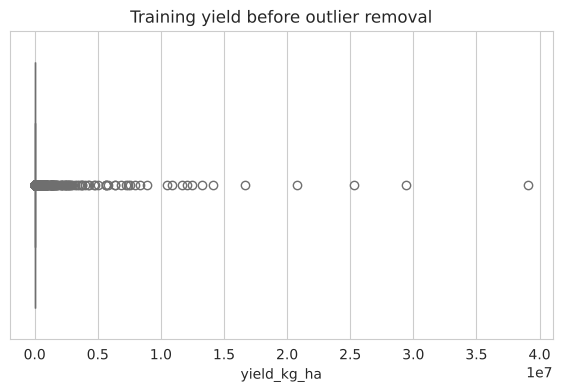

train      rows removed:

 532 of 34983
validation rows removed: 127 of 6982
test       rows removed: 128 of 6945


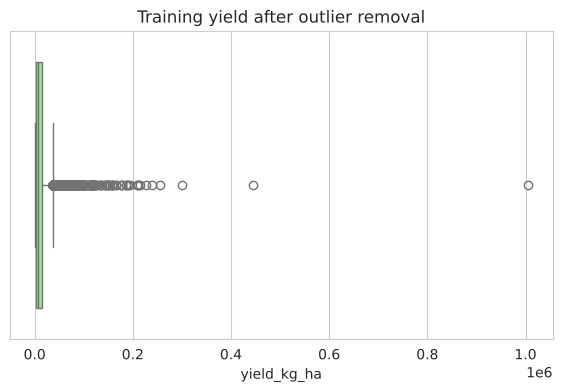

Final sizes -> train: 34451 | validation: 6855 | test: 6817


In [8]:
DEV_FACTOR = 8

# usual yield from the TRAINING years only
typical_pair = train_df.groupby(["country", "crop"])["yield_kg_ha"].median().rename("typical_pair")
typical_crop = train_df.groupby("crop")["yield_kg_ha"].median()

def keep_rows(data):
    pair_median = data.join(typical_pair, on=["country", "crop"])["typical_pair"]
    typical = pair_median.fillna(data["crop"].map(typical_crop))
    ratio = data["yield_kg_ha"] / typical
    return ratio.between(1 / DEV_FACTOR, DEV_FACTOR) | typical.isna()

plt.figure(figsize=(7, 4))
sns.boxplot(x=train_df["yield_kg_ha"], color="skyblue")
plt.title("Training yield before outlier removal")
plt.show()

for name, data in (("train", train_df), ("validation", val_df), ("test", test_df)):
    print(f"{name:10s} rows removed:", int((~keep_rows(data)).sum()), "of", len(data))

train_df = train_df[keep_rows(train_df)]
val_df = val_df[keep_rows(val_df)]
test_df = test_df[keep_rows(test_df)]

plt.figure(figsize=(7, 4))
sns.boxplot(x=train_df["yield_kg_ha"], color="lightgreen")
plt.title("Training yield after outlier removal")
plt.show()

print("Final sizes -> train:", len(train_df), "| validation:", len(val_df), "| test:", len(test_df))

## 6. Encoding and features

`flag` and `flag_desc` are descriptive metadata, so they are not used as predictors. Crop and country are one-hot encoded using pandas. Encoding only creates columns from the labels, so it is done on all rows together and then the rows are split back by year.

In [9]:
all_df = pd.concat([train_df, val_df, test_df])

model_df = all_df.drop(columns=["flag", "flag_desc"])
model_df = pd.get_dummies(model_df, columns=["crop", "country"], drop_first=True, dtype=int)

X = model_df.drop(columns=["yield_kg_ha"])
y = model_df["yield_kg_ha"]

X_train, y_train = X.loc[train_df.index], y.loc[train_df.index]
X_val, y_val = X.loc[val_df.index], y.loc[val_df.index]
X_test, y_test = X.loc[test_df.index], y.loc[test_df.index]

print("X_train:", X_train.shape)
print("X_val  :", X_val.shape)
print("X_test :", X_test.shape)

X_train: (34451, 177)
X_val  : (6855, 177)
X_test : (6817, 177)


## 6. Exploratory Data Analysis (training years only)

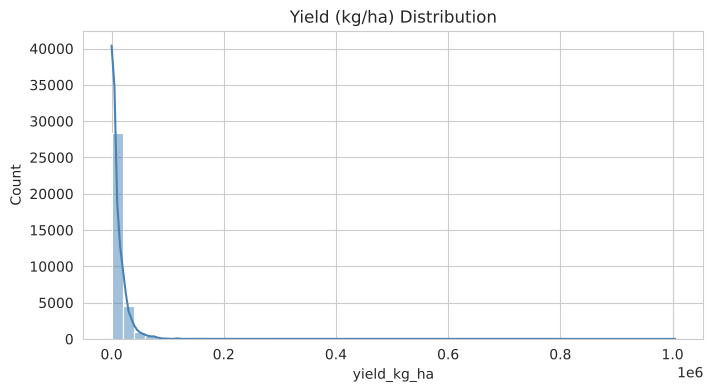

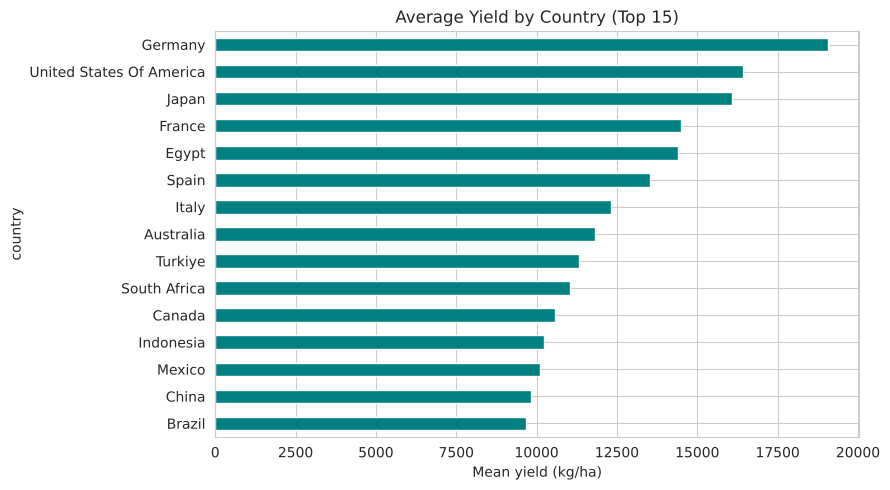

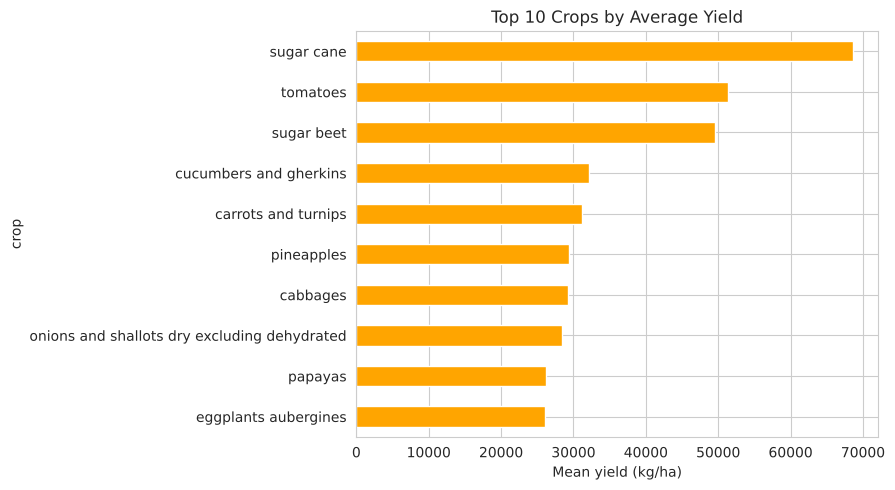

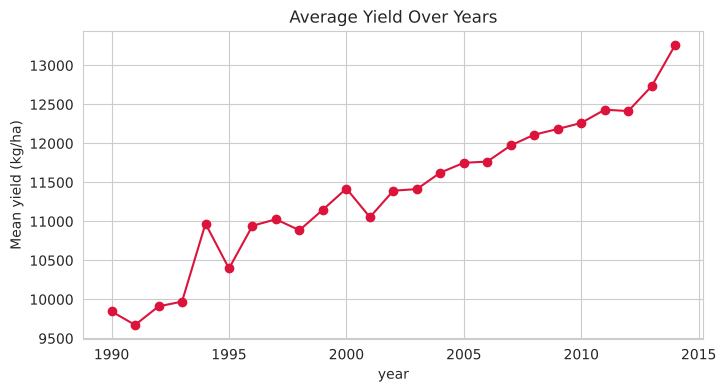

In [10]:
# 6.1 Yield distribution
plt.figure(figsize=(8, 4))
sns.histplot(train_df["yield_kg_ha"], bins=50, kde=True, color="steelblue")
plt.title("Yield (kg/ha) Distribution")
plt.show()

# 6.2 Average yield by country (top 15)
plt.figure(figsize=(9, 5))
train_df.groupby("country")["yield_kg_ha"].mean().sort_values().tail(15).plot(kind="barh", color="teal")
plt.xlabel("Mean yield (kg/ha)")
plt.title("Average Yield by Country (Top 15)")
plt.tight_layout()
plt.show()

# 6.3 Top 10 crops by average yield
plt.figure(figsize=(9, 5))
train_df.groupby("crop")["yield_kg_ha"].mean().sort_values(ascending=False).head(10)[::-1].plot(kind="barh", color="orange")
plt.xlabel("Mean yield (kg/ha)")
plt.title("Top 10 Crops by Average Yield")
plt.tight_layout()
plt.show()

# 6.4 Yield trend over years
train_df.groupby("year")["yield_kg_ha"].mean().plot(marker="o", figsize=(8, 4), color="crimson")
plt.ylabel("Mean yield (kg/ha)")
plt.title("Average Yield Over Years")
plt.show()

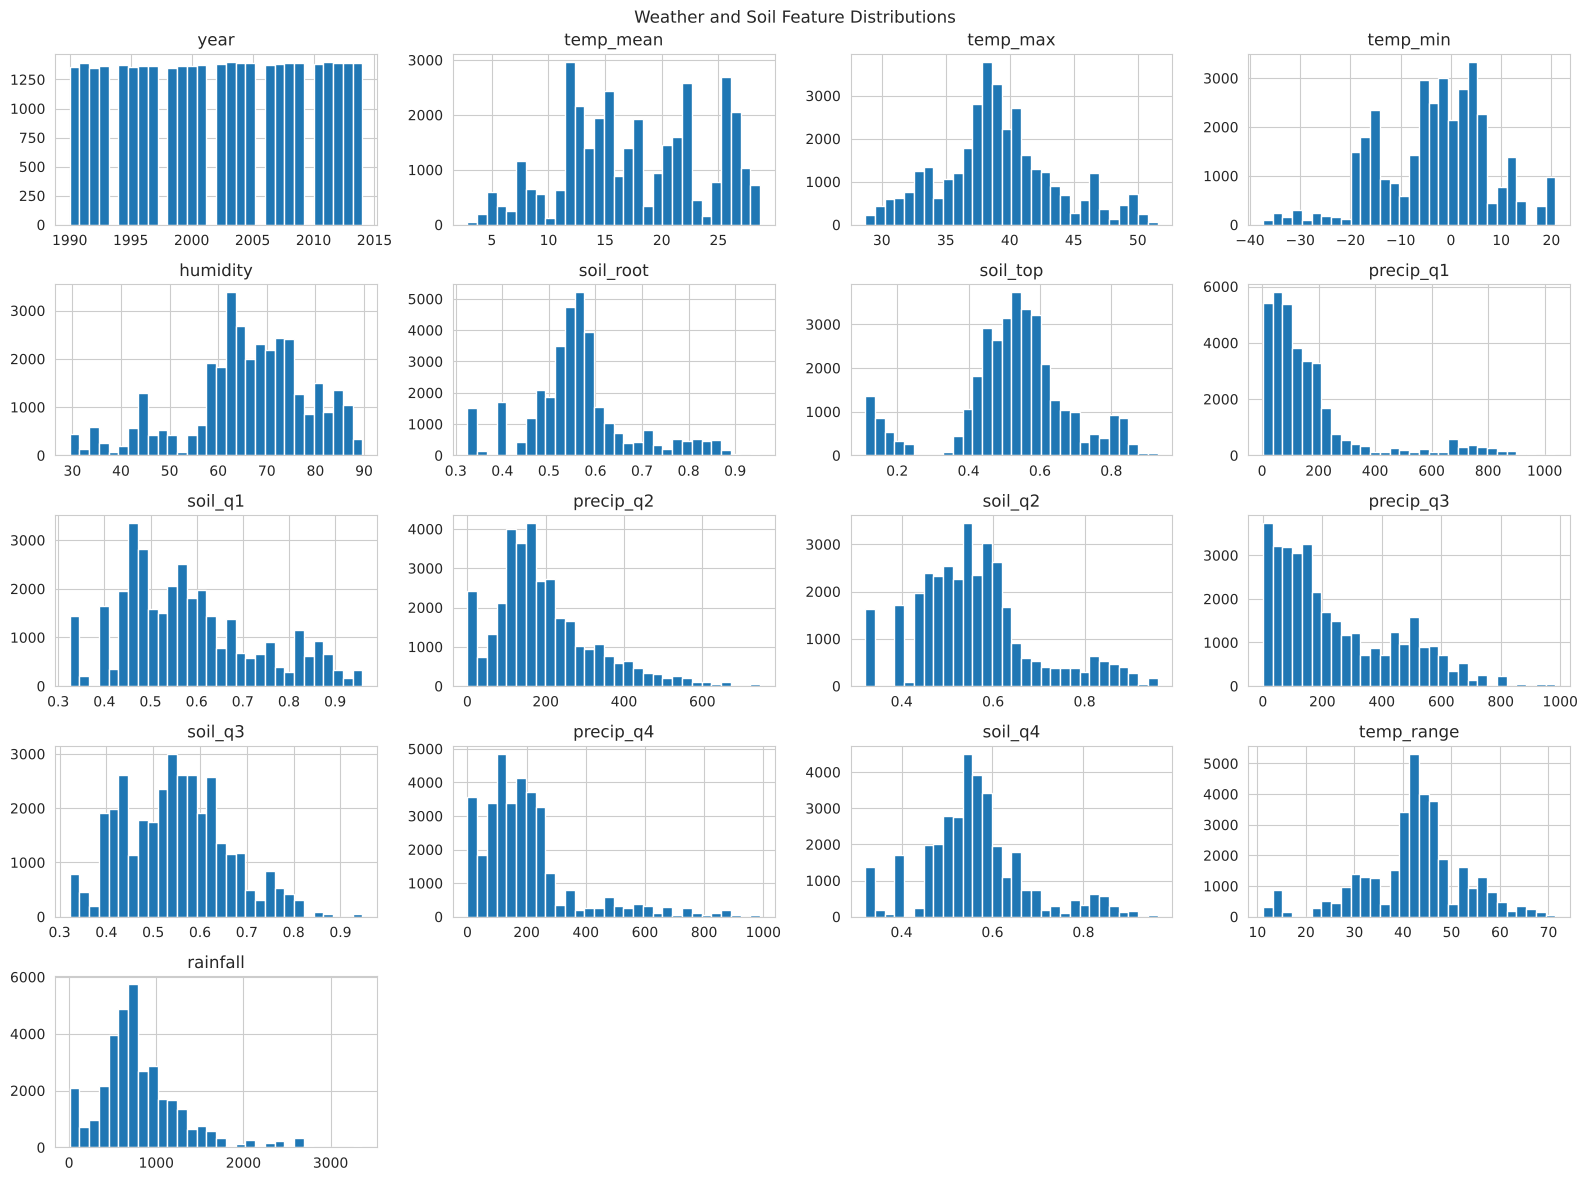

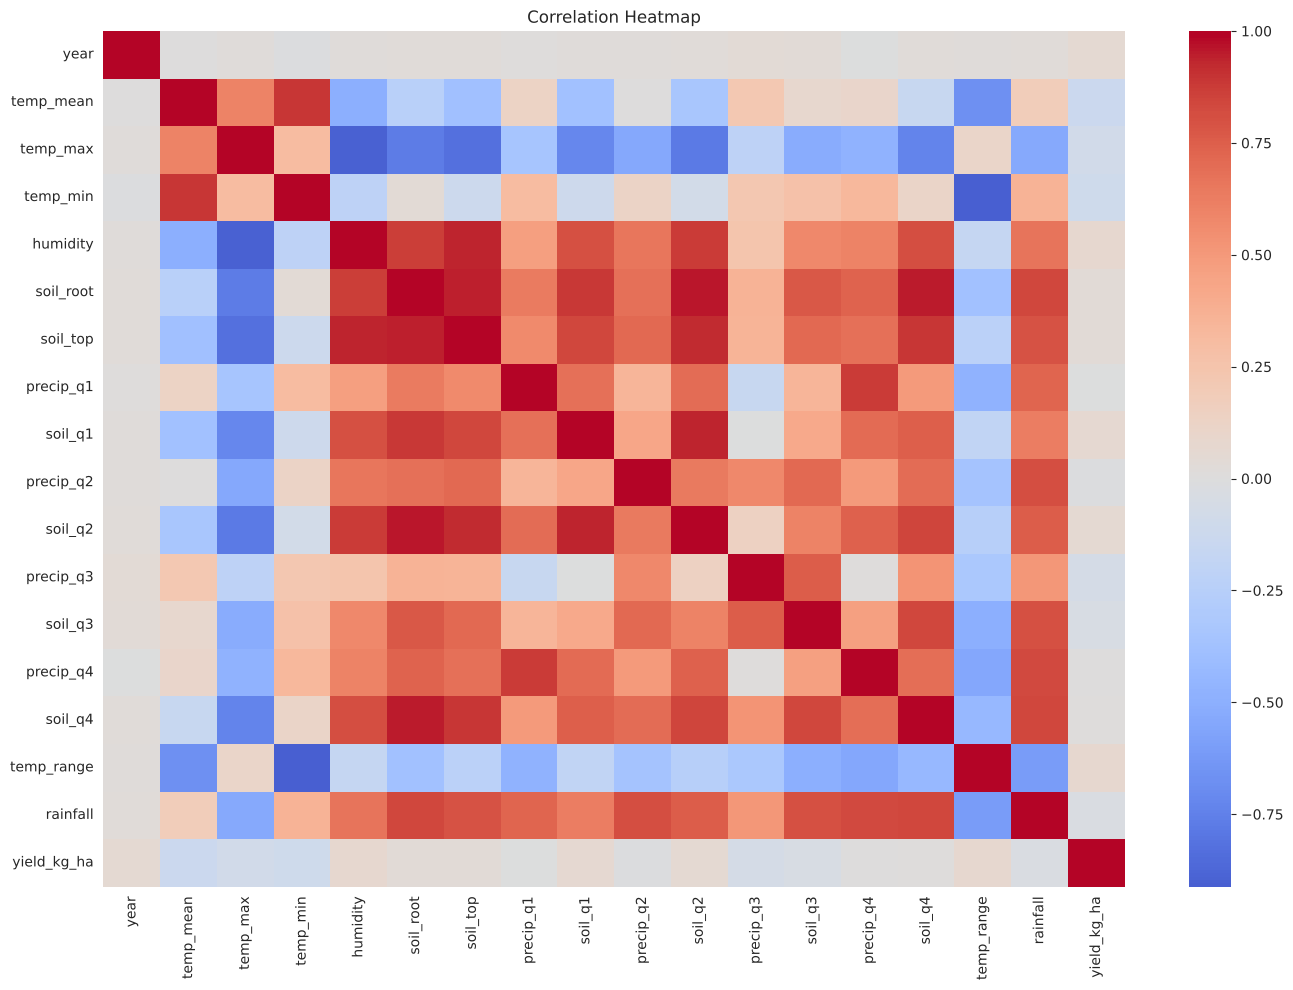

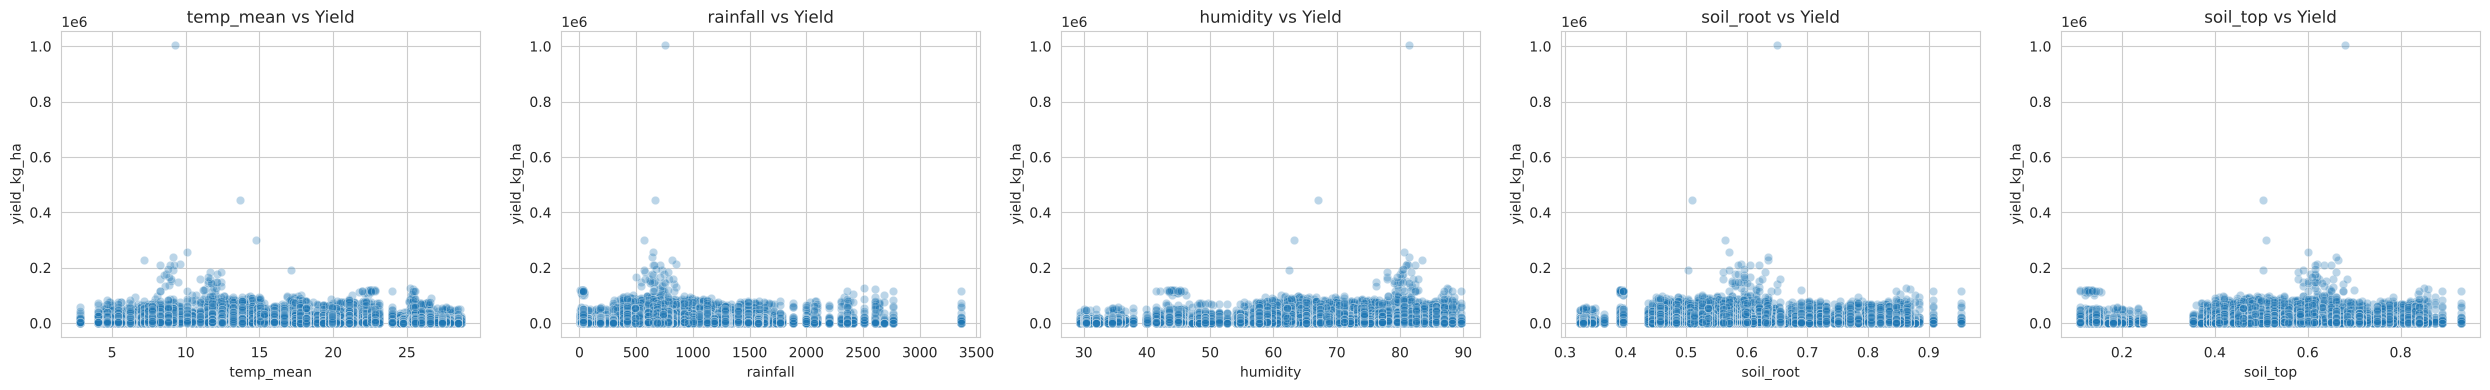

In [11]:
# 6.5 Distributions of numeric weather/soil predictors
numeric_predictors = [
    c for c in train_df.select_dtypes(include=np.number).columns
    if c != "yield_kg_ha"
]
train_df[numeric_predictors].hist(bins=30, figsize=(16, 12))
plt.suptitle("Weather and Soil Feature Distributions")
plt.tight_layout()
plt.show()

# 6.6 Correlation heatmap
corr_cols = numeric_predictors + ["yield_kg_ha"]
plt.figure(figsize=(14, 10))
sns.heatmap(train_df[corr_cols].corr(), cmap="coolwarm", center=0)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

# 6.7 Selected weather/soil features vs yield
selected_features = [c for c in ["temp_mean", "rainfall", "humidity", "soil_root", "soil_top"] if c in train_df.columns]
fig, axes = plt.subplots(1, len(selected_features), figsize=(5 * len(selected_features), 4))
if len(selected_features) == 1:
    axes = [axes]
for ax, feature in zip(axes, selected_features):
    sns.scatterplot(data=train_df, x=feature, y="yield_kg_ha", alpha=0.3, ax=ax)
    ax.set_title(f"{feature} vs Yield")
plt.tight_layout()
plt.show()

## 7. Evaluation helper and shared functions

In [12]:
def evaluate_model(model_name, y_train, train_pred,
                   y_val, val_pred, y_test, test_pred):

    results = []

    datasets = [
        ("Training", y_train, train_pred),
        ("Validation", y_val, val_pred),
        ("Testing", y_test, test_pred)
    ]

    for dataset_name, y_true, y_pred in datasets:
        mae = mean_absolute_error(y_true, y_pred)
        rmse = mean_squared_error(y_true, y_pred) ** 0.5
        r2 = r2_score(y_true, y_pred)

        print(f"{model_name} - {dataset_name}")
        print("MAE  :", round(mae, 2))
        print("RMSE :", round(rmse, 2))
        print("R2   :", round(r2, 4))
        print("-" * 45)

        results.append({
            "Model": model_name,
            "Dataset": dataset_name,
            "MAE": mae,
            "RMSE": rmse,
            "R2": r2
        })

    return results

In [13]:
results = []            # metrics of every model
fitted_models = {}      # every fitted model, by name (used for the final comparison and for saving)
cv = TimeSeriesSplit(n_splits=3)   # training rows are sorted by year: each fold trains on earlier years, validates on later years

# numeric weather/soil columns (the crop_ and country_ dummy columns are not scaled or expanded)
numeric_features = [c for c in X_train.columns if not c.startswith(("crop_", "country_"))]
print("Numeric features:", len(numeric_features))


def make_model(regressor, degree=1):
    """scale numeric columns -> (polynomial features) -> regressor, trained on log1p(yield)"""
    steps = [StandardScaler()]
    if degree > 1:
        steps += [PolynomialFeatures(degree, include_bias=False), StandardScaler()]
    prep = ColumnTransformer(
        [("num", make_pipeline(*steps), numeric_features)],
        remainder="passthrough"           # dummy columns pass through unchanged
    )
    return TransformedTargetRegressor(
        regressor=Pipeline([("prep", prep), ("model", regressor)]),
        func=np.log1p,
        inverse_func=np.expm1
    )


def plot_actual_vs_predicted(name, y_pred):
    plt.figure(figsize=(7, 5))
    plt.scatter(y_test, y_pred, alpha=0.4)
    plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color="red")
    plt.xlabel("Actual Yield (kg/ha)")
    plt.ylabel("Predicted Yield (kg/ha)")
    plt.title(f"{name}: Actual vs Predicted (Test Data)")
    plt.tight_layout()
    plt.show()


def evaluate_and_plot(name, model):
    fitted_models[name] = model
    results.extend(evaluate_model(
        name,
        y_train, model.predict(X_train),
        y_val, model.predict(X_val),
        y_test, model.predict(X_test)
    ))
    plot_actual_vs_predicted(name, model.predict(X_test))


def tune_alpha(regressor, alphas, degree=1):
    """GridSearchCV over the penalty strength alpha (Ridge or Lasso)"""
    grid = GridSearchCV(
        make_model(regressor, degree),
        param_grid={"regressor__model__alpha": alphas},
        scoring="r2", cv=cv, n_jobs=-1
    )
    grid.fit(X_train, y_train)

    table = pd.DataFrame({"alpha": alphas, "mean CV R2": grid.cv_results_["mean_test_score"]})
    display(table)

    plt.figure(figsize=(6, 4))
    plt.semilogx(table["alpha"], table["mean CV R2"], marker="o", color="purple")
    plt.xlabel("alpha (log scale)")
    plt.ylabel("Mean CV R2")
    plt.title("Cross-validation R2 for each alpha")
    plt.tight_layout()
    plt.show()

    print("Best alpha:", grid.best_params_["regressor__model__alpha"], "| best CV R2:", round(grid.best_score_, 4))
    return grid


def show_top_coefficients(grid, title, top=15):
    pipe = grid.best_estimator_.regressor_
    names = [n.replace("num__", "").replace("remainder__", "") for n in pipe.named_steps["prep"].get_feature_names_out()]
    coefs = pd.Series(pipe.named_steps["model"].coef_, index=names)
    print("Non-zero coefficients:", int((coefs != 0).sum()), "of", len(coefs))

    plt.figure(figsize=(9, 6))
    coefs[coefs.abs().sort_values().tail(top).index].plot(kind="barh", color="seagreen")
    plt.xlabel("Coefficient (on log yield, scaled features)")
    plt.title(title)
    plt.tight_layout()
    plt.show()

Numeric features: 17


## 8. Linear models

### 8.1 Linear Regression

Linear Regression - Training
MAE  : 3765.48
RMSE : 9753.03
R2   : 0.6283
---------------------------------------------
Linear Regression - Validation
MAE  : 4725.05
RMSE : 10530.25
R2   : 0.6506
---------------------------------------------
Linear Regression - Testing
MAE  : 5023.06
RMSE : 11213.38
R2   : 0.6302
---------------------------------------------


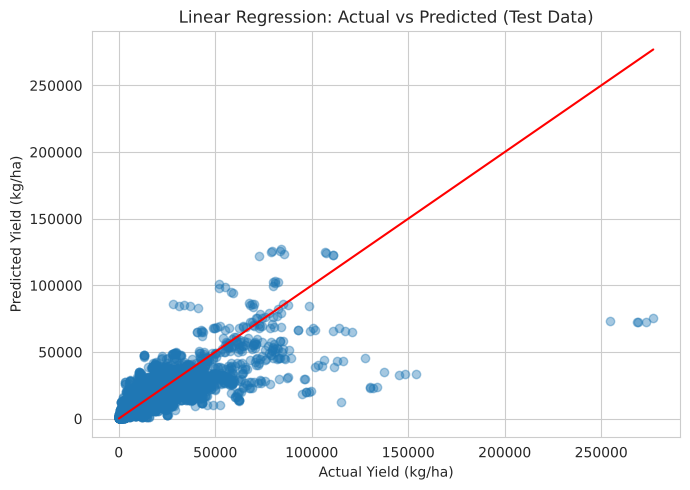

,Model,Dataset,MAE,RMSE,R2
0,Linear Regression,Training,3765.483507,9753.025923,0.628254
1,Linear Regression,Validation,4725.047383,10530.247557,0.650620
2,Linear Regression,Testing,5023.058998,11213.380805,0.630178


In [14]:
linear_model = make_model(LinearRegression())
linear_model.fit(X_train, y_train)

evaluate_and_plot("Linear Regression", linear_model)
display(pd.DataFrame(results))

### 8.2 Linear Regression + Ridge

Ridge adds a penalty on the size of the coefficients (alpha). A larger alpha shrinks the coefficients more. The best alpha is chosen by time-ordered cross-validation on the training years.

,alpha,mean CV R2
0,0.001,0.668280
1,0.010,0.668238
2,0.100,0.667941
3,1.000,0.665905
4,10.000,0.637537
5,100.000,0.351935


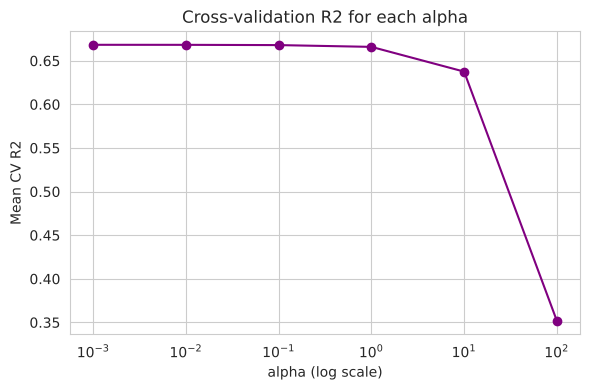

Best alpha: 0.001 | best CV R2: 0.6683
Linear + Ridge - Training
MAE  : 3765.49
RMSE : 9753.05
R2   : 0.6283
---------------------------------------------
Linear + Ridge - Validation
MAE  : 4725.06
RMSE : 10530.3
R2   : 0.6506
---------------------------------------------
Linear + Ridge - Testing
MAE  : 5023.07
RMSE : 11213.43
R2   : 0.6302
---------------------------------------------


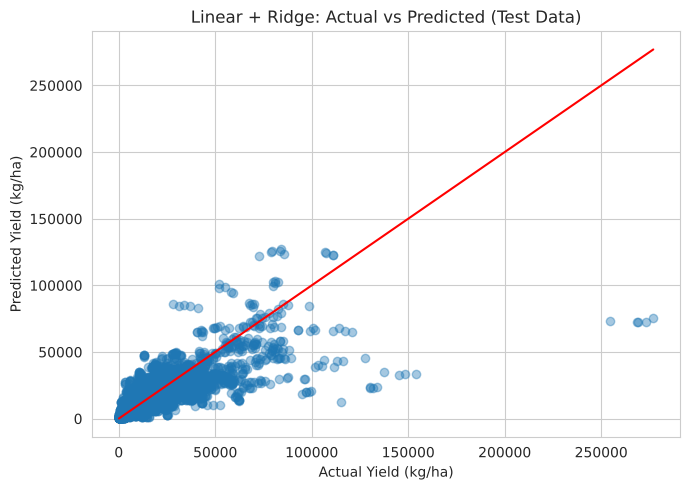

Non-zero coefficients: 177 of 177


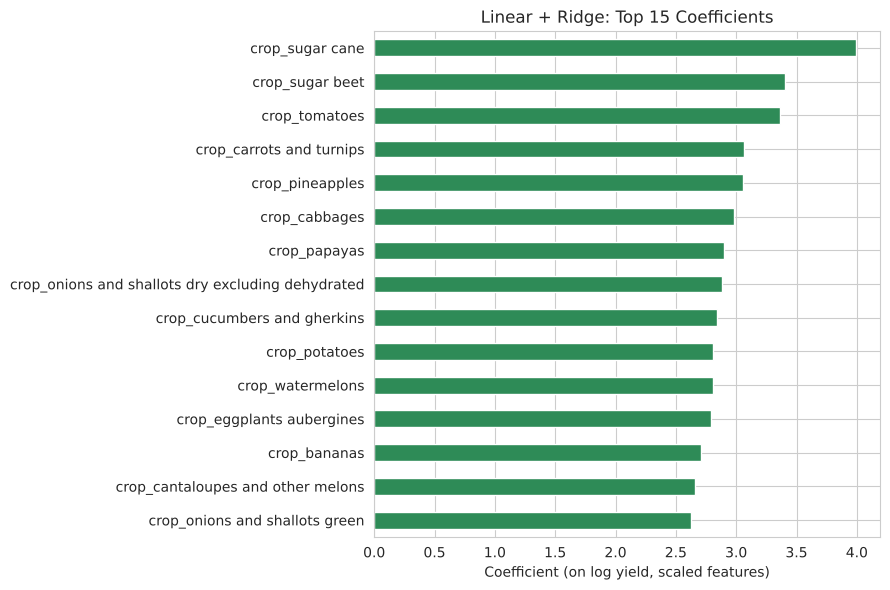

In [15]:
ridge_alphas = [0.001, 0.01, 0.1, 1, 10, 100]

ridge_grid = tune_alpha(Ridge(), ridge_alphas)

evaluate_and_plot("Linear + Ridge", ridge_grid)
show_top_coefficients(ridge_grid, "Linear + Ridge: Top 15 Coefficients")

### 8.3 Linear Regression + Lasso

Lasso uses an absolute-value penalty, which can set coefficients exactly to zero, so it also selects features.

,alpha,mean CV R2
0,0.00001,0.667885
1,0.00010,0.665553
2,0.00100,0.640107
3,0.01000,0.156583


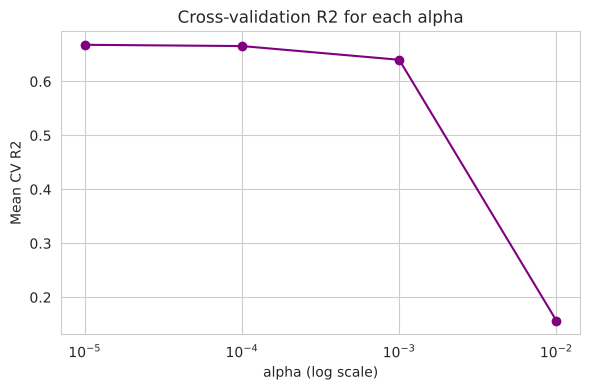

Best alpha: 1e-05 | best CV R2: 0.6679
Linear + Lasso - Training
MAE  : 3766.33
RMSE : 9756.98
R2   : 0.628
---------------------------------------------
Linear + Lasso - Validation
MAE  : 4726.32
RMSE : 10538.94
R2   : 0.65
---------------------------------------------
Linear + Lasso - Testing
MAE  : 5023.08
RMSE : 11223.75
R2   : 0.6295
---------------------------------------------


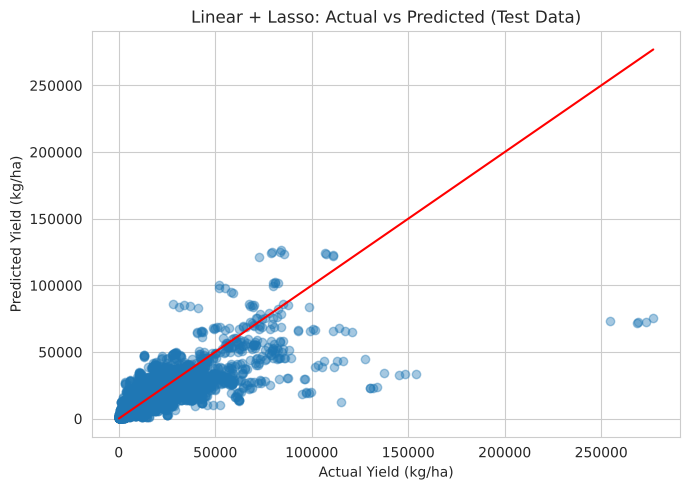

Non-zero coefficients: 174 of 177


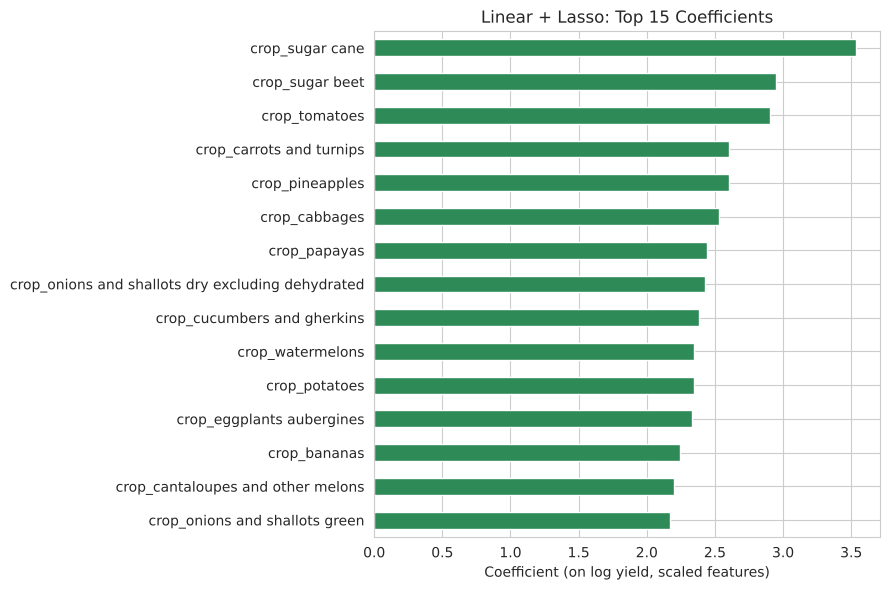

In [16]:
lasso_alphas = [0.00001, 0.0001, 0.001, 0.01]

lasso_grid = tune_alpha(Lasso(max_iter=20000), lasso_alphas)

evaluate_and_plot("Linear + Lasso", lasso_grid)
show_top_coefficients(lasso_grid, "Linear + Lasso: Top 15 Coefficients")

## 9. Polynomial models

Polynomial regression adds squares and products of the 17 numeric weather/soil columns (for example `temp_mean × rainfall`), so the model can learn curved effects and interactions between weather variables.

### 9.0 Choosing the degree

Degree 1 is ordinary linear regression. The plain polynomial model is fitted with degrees 1, 2 and 3 and compared on the **validation** set only.

,degree,n_features,Train R2,Validation R2,Validation RMSE
0,1,177,0.628254,0.650620,10530.247557
1,2,330,0.629216,0.639795,10692.137902
2,3,1299,0.629921,0.524783,12281.058679


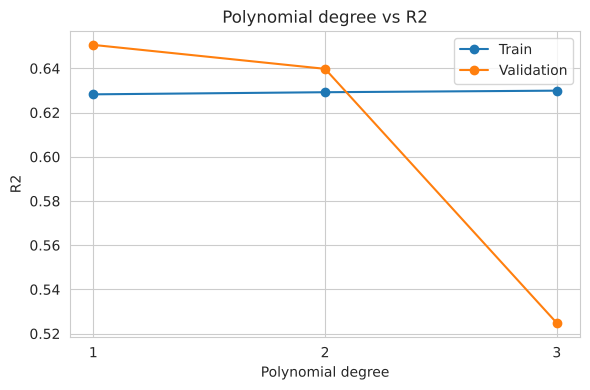

In [17]:
degree_rows = []
for degree in [1, 2, 3]:
    m = make_model(LinearRegression(), degree)
    m.fit(X_train, y_train)
    degree_rows.append({
        "degree": degree,
        "n_features": m.regressor_.named_steps["model"].coef_.shape[0],
        "Train R2": r2_score(y_train, m.predict(X_train)),
        "Validation R2": r2_score(y_val, m.predict(X_val)),
        "Validation RMSE": mean_squared_error(y_val, m.predict(X_val)) ** 0.5
    })

degree_df = pd.DataFrame(degree_rows)
display(degree_df)

plt.figure(figsize=(6, 4))
plt.plot(degree_df["degree"], degree_df["Train R2"], marker="o", label="Train")
plt.plot(degree_df["degree"], degree_df["Validation R2"], marker="o", label="Validation")
plt.xticks([1, 2, 3])
plt.xlabel("Polynomial degree")
plt.ylabel("R2")
plt.title("Polynomial degree vs R2")
plt.legend()
plt.tight_layout()
plt.show()

Degree 2 is used for all polynomial models below. It is the smallest degree that adds curves and interactions, while degree 3 creates 1,299 columns and overfits (its validation R² drops well below its training R²). Note that on this data the degree 2 polynomial is not better than the plain linear model (degree 1) on validation.

### 9.1 Polynomial Regression (degree 2)

Polynomial Regression - Training
MAE  : 3757.03
RMSE : 9740.41
R2   : 0.6292
---------------------------------------------
Polynomial Regression - Validation
MAE  : 4774.44
RMSE : 10692.14
R2   : 0.6398
---------------------------------------------
Polynomial Regression - Testing
MAE  : 5081.79
RMSE : 11418.49
R2   : 0.6165
---------------------------------------------


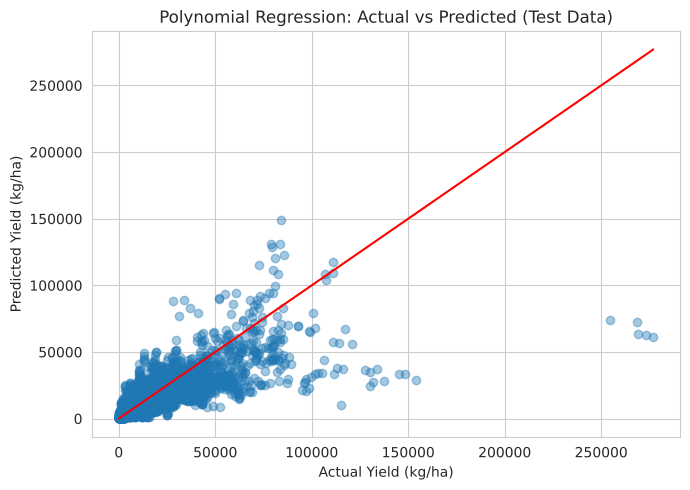

,Model,Dataset,MAE,RMSE,R2
0,Linear Regression,Training,3765.483507,9753.025923,0.628254
1,Linear Regression,Validation,4725.047383,10530.247557,0.650620
2,Linear Regression,Testing,5023.058998,11213.380805,0.630178
3,Linear + Ridge,Training,3765.486451,9753.051685,0.628252
4,Linear + Ridge,Validation,4725.059370,10530.295030,0.650617
5,Linear + Ridge,Testing,5023.065988,11213.429442,0.630175
6,Linear + Lasso,Training,3766.333425,9756.978545,0.627953
7,Linear + Lasso,Validation,4726.319537,10538.935109,0.650043
8,Linear + Lasso,Testing,5023.082314,11223.747991,0.629494
9,Polynomial Regression,Training,3757.028549,9740.408917,0.629216


In [18]:
POLY_DEGREE = 2

poly_model = make_model(LinearRegression(), POLY_DEGREE)
poly_model.fit(X_train, y_train)

evaluate_and_plot("Polynomial Regression", poly_model)
display(pd.DataFrame(results))

### 9.2 Polynomial Regression + Ridge

,alpha,mean CV R2
0,0.001,0.538448
1,0.010,0.601628
2,0.100,0.643749
3,1.000,0.662713
4,10.000,0.642168
5,100.000,0.369951


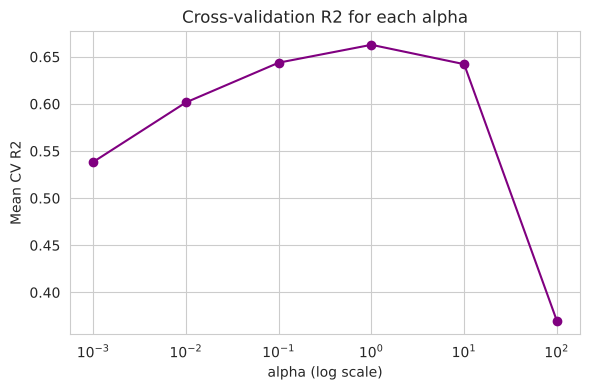

Best alpha: 1 | best CV R2: 0.6627
Polynomial + Ridge - Training
MAE  : 3760.49
RMSE : 9752.97
R2   : 0.6283
---------------------------------------------
Polynomial + Ridge - Validation
MAE  : 4779.21
RMSE : 10703.2
R2   : 0.639
---------------------------------------------
Polynomial + Ridge - Testing
MAE  : 5067.23
RMSE : 11433.13
R2   : 0.6155
---------------------------------------------


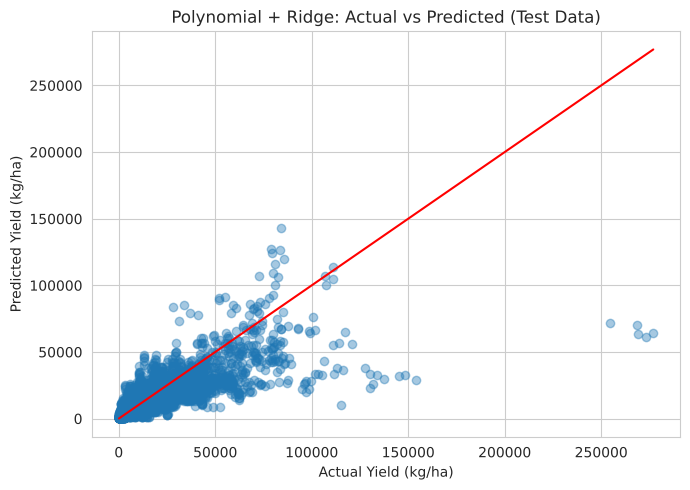

Non-zero coefficients: 330 of 330


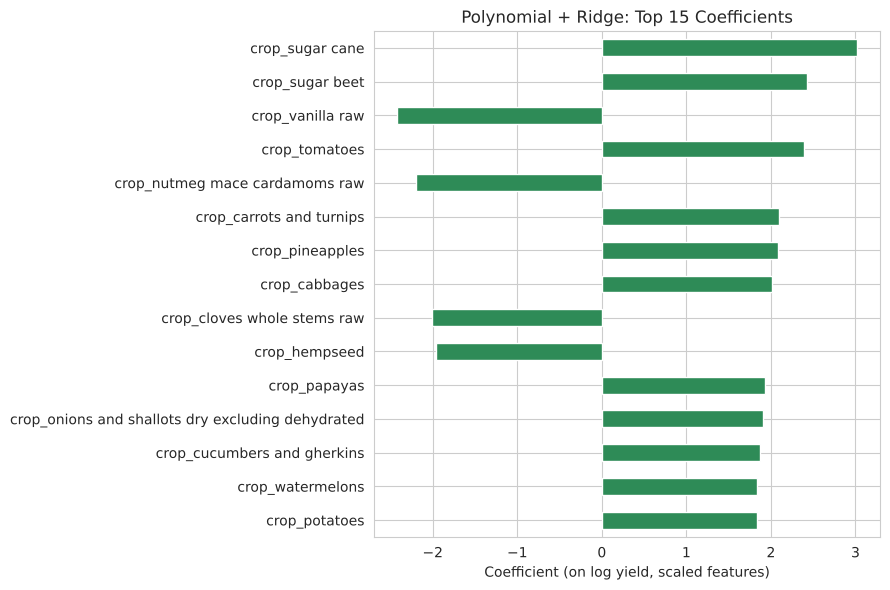

In [19]:
poly_ridge_grid = tune_alpha(Ridge(), ridge_alphas, POLY_DEGREE)

evaluate_and_plot("Polynomial + Ridge", poly_ridge_grid)
show_top_coefficients(poly_ridge_grid, "Polynomial + Ridge: Top 15 Coefficients")

### 9.3 Polynomial Regression + Lasso

,alpha,mean CV R2
0,0.0001,0.668089
1,0.0003,0.663937
2,0.0010,0.644000
3,0.0030,0.556128
4,0.0100,0.172977


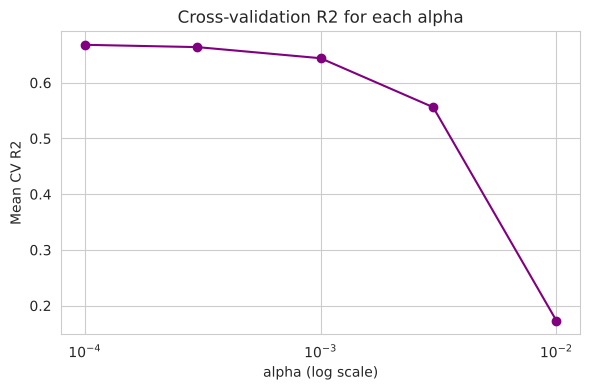

Best alpha: 0.0001 | best CV R2: 0.6681


Polynomial + Lasso - Training
MAE  : 3765.07
RMSE : 9768.76
R2   : 0.6271
---------------------------------------------
Polynomial + Lasso - Validation
MAE  : 4764.4
RMSE : 10671.1
R2   : 0.6412
---------------------------------------------
Polynomial + Lasso - Testing
MAE  : 5050.13
RMSE : 11366.24
R2   : 0.62
---------------------------------------------


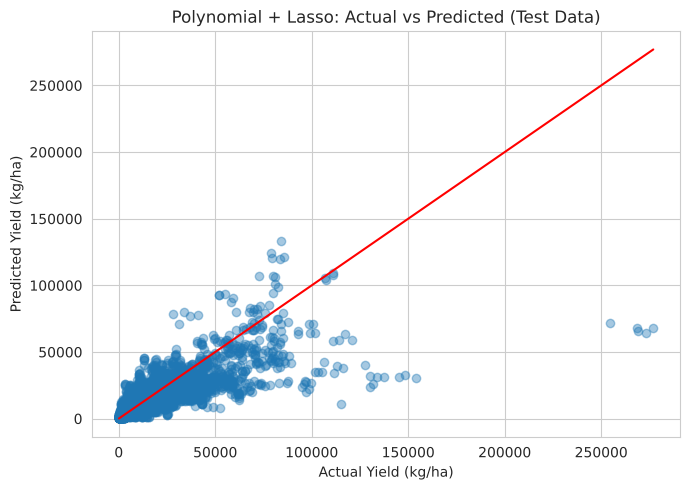

Non-zero coefficients: 227 of 330


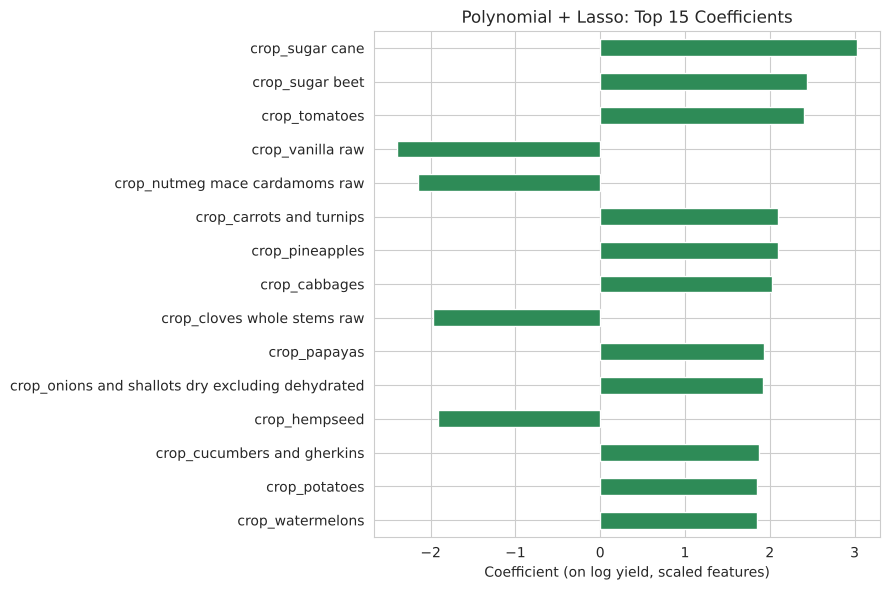

In [20]:
# the smallest alpha (0.00001) does not converge with 330 polynomial columns, so the grid starts at 0.0001
poly_lasso_alphas = [0.0001, 0.0003, 0.001, 0.003, 0.01]

poly_lasso_grid = tune_alpha(Lasso(max_iter=20000), poly_lasso_alphas, POLY_DEGREE)

evaluate_and_plot("Polynomial + Lasso", poly_lasso_grid)
show_top_coefficients(poly_lasso_grid, "Polynomial + Lasso: Top 15 Coefficients")

## 10. Decision Tree

A decision tree splits the data again and again with yes/no questions (for example "is the crop wheat?", "is the year after 2005?"). It can learn crop-by-country effects directly, which linear models cannot. Trees do not need feature scaling, so the encoded features are used as they are.

### 10.1 Decision Tree (untuned)

An untuned tree grows until every leaf is pure, so it usually fits the training data perfectly and overfits.

Decision Tree (untuned) - Training
MAE  : 0.0
RMSE : 0.0
R2   : 1.0
---------------------------------------------
Decision Tree (untuned) - Validation
MAE  : 2205.89
RMSE : 5760.36
R2   : 0.8955
---------------------------------------------
Decision Tree (untuned) - Testing
MAE  : 2964.01
RMSE : 7498.26
R2   : 0.8346
---------------------------------------------


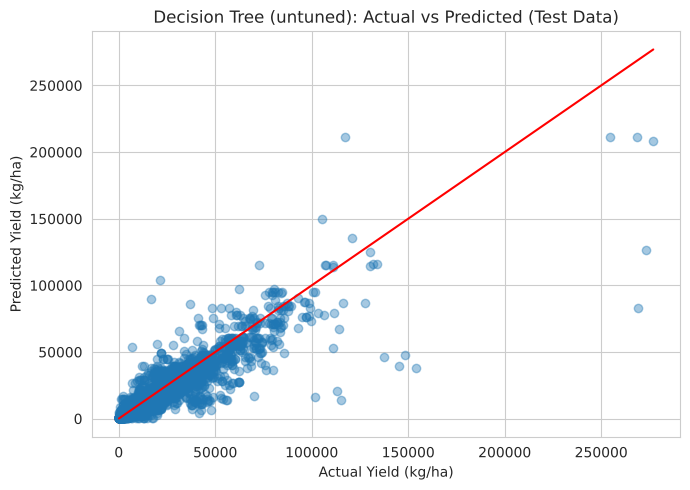

,Model,Dataset,MAE,RMSE,R2
0,Linear Regression,Training,3.765484e+03,9.753026e+03,0.628254
1,Linear Regression,Validation,4.725047e+03,1.053025e+04,0.650620
2,Linear Regression,Testing,5.023059e+03,1.121338e+04,0.630178
3,Linear + Ridge,Training,3.765486e+03,9.753052e+03,0.628252
4,Linear + Ridge,Validation,4.725059e+03,1.053030e+04,0.650617
5,Linear + Ridge,Testing,5.023066e+03,1.121343e+04,0.630175
6,Linear + Lasso,Training,3.766333e+03,9.756979e+03,0.627953
7,Linear + Lasso,Validation,4.726320e+03,1.053894e+04,0.650043
8,Linear + Lasso,Testing,5.023082e+03,1.122375e+04,0.629494
9,Polynomial Regression,Training,3.757029e+03,9.740409e+03,0.629216


In [21]:
dt_model = TransformedTargetRegressor(
    regressor=DecisionTreeRegressor(random_state=42),
    func=np.log1p,
    inverse_func=np.expm1
)
dt_model.fit(X_train, y_train)

evaluate_and_plot("Decision Tree (untuned)", dt_model)
display(pd.DataFrame(results))

### 10.2 Decision Tree + GridSearchCV

- `max_depth`: maximum depth of the tree (limits overfitting)
- `min_samples_leaf`: minimum rows in a leaf
- `min_samples_split`: minimum rows needed to split a node

The best combination is selected with time-ordered 3-fold cross-validation on the training years only, scored with R² in kg/ha.

Decision Tree best parameters: {'regressor__max_depth': None, 'regressor__min_samples_leaf': 5, 'regressor__min_samples_split': 2}
Decision Tree best CV R2: 0.8371


,params,mean_test_score,rank_test_score
36,"{'regressor__max_depth': None, 'regressor__min...",0.837063,1
37,"{'regressor__max_depth': None, 'regressor__min...",0.837063,1
35,"{'regressor__max_depth': None, 'regressor__min...",0.822646,3
34,"{'regressor__max_depth': None, 'regressor__min...",0.795671,4
39,"{'regressor__max_depth': None, 'regressor__min...",0.792791,5


Decision Tree + GridSearchCV - Training
MAE  : 851.75
RMSE : 5197.48
R2   : 0.8944
---------------------------------------------
Decision Tree + GridSearchCV - Validation
MAE  : 2270.52
RMSE : 6062.72
R2   : 0.8842
---------------------------------------------
Decision Tree + GridSearchCV - Testing
MAE  : 2903.05
RMSE : 7099.79
R2   : 0.8517
---------------------------------------------


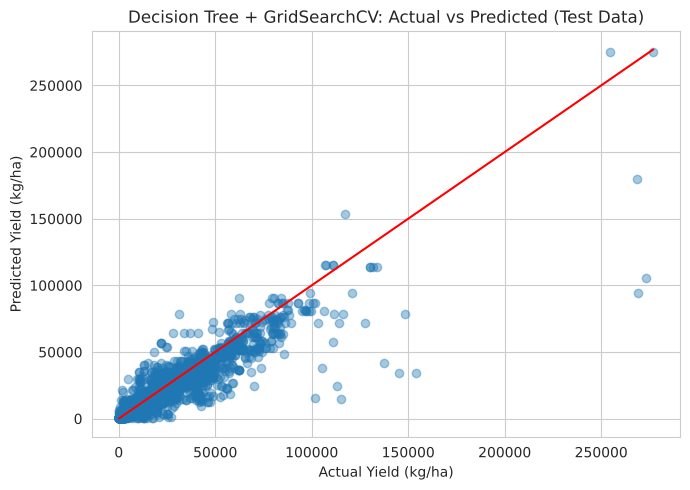

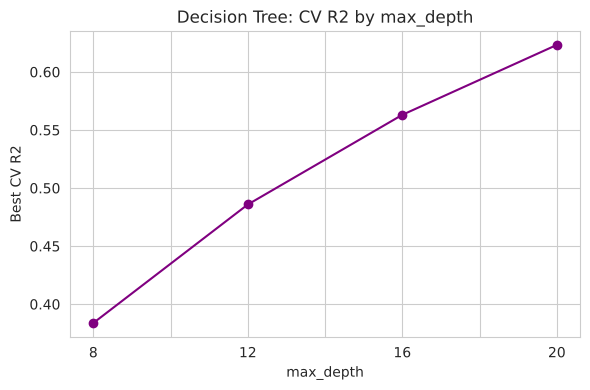

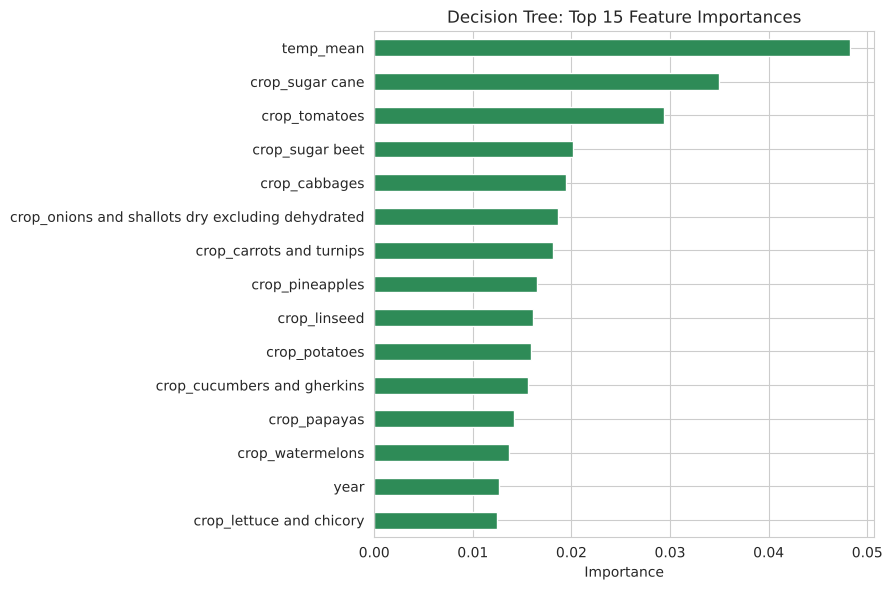

In [22]:
dt_param_grid = {
    "regressor__max_depth": [8, 12, 16, 20, None],
    "regressor__min_samples_leaf": [1, 2, 5, 10],
    "regressor__min_samples_split": [2, 10]
}

dt_grid = GridSearchCV(
    estimator=TransformedTargetRegressor(
        regressor=DecisionTreeRegressor(random_state=42),
        func=np.log1p,
        inverse_func=np.expm1
    ),
    param_grid=dt_param_grid,
    scoring="r2",
    cv=cv,
    n_jobs=-1
)
dt_grid.fit(X_train, y_train)

print("Decision Tree best parameters:", dt_grid.best_params_)
print("Decision Tree best CV R2:", round(dt_grid.best_score_, 4))

# Top 5 parameter combinations
cv_table = pd.DataFrame(dt_grid.cv_results_)[["params", "mean_test_score", "rank_test_score"]]
display(cv_table.sort_values("rank_test_score").head(5))

evaluate_and_plot("Decision Tree + GridSearchCV", dt_grid)

# CV R2 for each max_depth (best other parameters for that depth)
depth_table = pd.DataFrame(dt_grid.cv_results_)
depth_table["max_depth"] = depth_table["param_regressor__max_depth"].astype(str)
depth_best = depth_table.groupby("max_depth")["mean_test_score"].max().reindex(["8", "12", "16", "20", "None"])

plt.figure(figsize=(6, 4))
depth_best.plot(marker="o", color="purple")
plt.xlabel("max_depth")
plt.ylabel("Best CV R2")
plt.title("Decision Tree: CV R2 by max_depth")
plt.tight_layout()
plt.show()

# Top 15 feature importances
best_tree = dt_grid.best_estimator_.regressor_
importances = pd.Series(best_tree.feature_importances_, index=X_train.columns)
plt.figure(figsize=(9, 6))
importances.sort_values().tail(15).plot(kind="barh", color="seagreen")
plt.xlabel("Importance")
plt.title("Decision Tree: Top 15 Feature Importances")
plt.tight_layout()
plt.show()

## 11. Compare all models

Models are ranked on the **validation** set. The test set is shown for the final comparison only.

Dataset,Training,Validation,Testing
Model,,,
Decision Tree (untuned),1.0000,0.8955,0.8346
Decision Tree + GridSearchCV,0.8944,0.8842,0.8517
Linear + Lasso,0.6280,0.6500,0.6295
Linear + Ridge,0.6283,0.6506,0.6302
Linear Regression,0.6283,0.6506,0.6302
Polynomial + Lasso,0.6271,0.6412,0.6200
Polynomial + Ridge,0.6283,0.6390,0.6155
Polynomial Regression,0.6292,0.6398,0.6165


,Model,Dataset,MAE,RMSE,R2
19,Decision Tree (untuned),Validation,2205.887177,5760.360606,0.895451
22,Decision Tree + GridSearchCV,Validation,2270.518825,6062.716320,0.884188
1,Linear Regression,Validation,4725.047383,10530.247557,0.650620
4,Linear + Ridge,Validation,4725.059370,10530.295030,0.650617
7,Linear + Lasso,Validation,4726.319537,10538.935109,0.650043
16,Polynomial + Lasso,Validation,4764.398617,10671.101158,0.641211
10,Polynomial Regression,Validation,4774.439155,10692.137902,0.639795
13,Polynomial + Ridge,Validation,4779.214131,10703.200209,0.639049


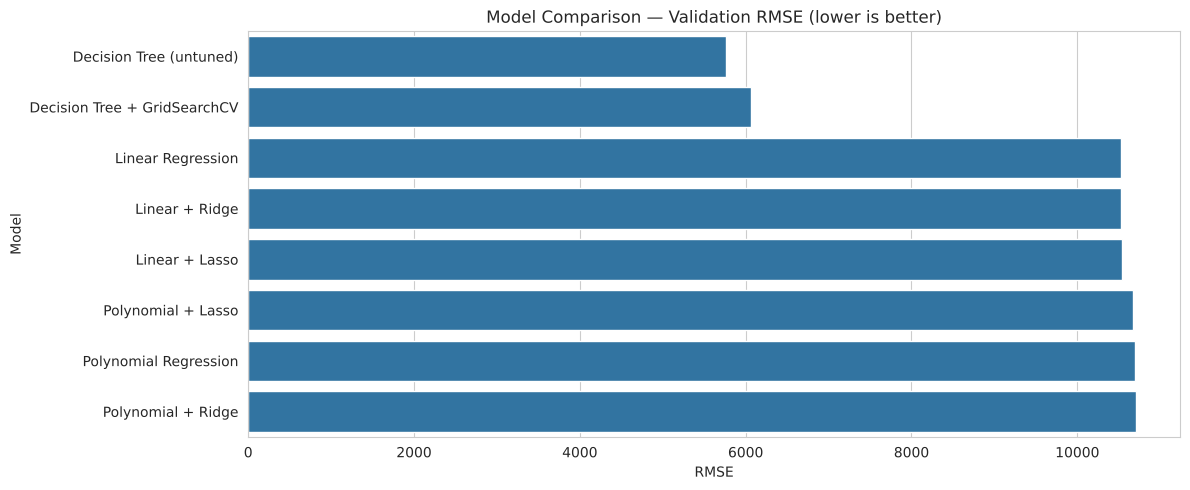

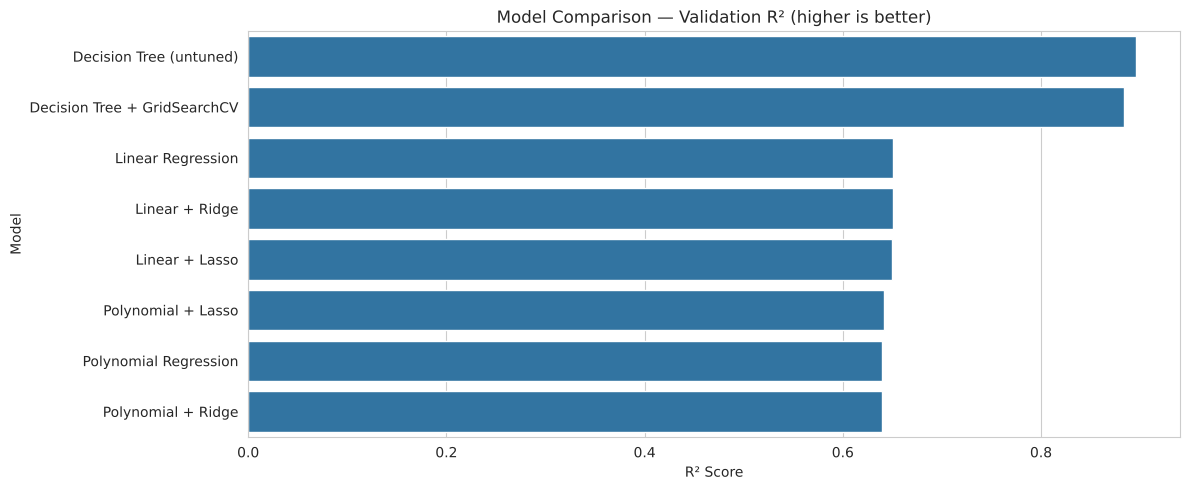

Best model on the validation set: Decision Tree (untuned)
Its test results -> MAE: 2964.0 | RMSE: 7498.3 | R2: 0.8346


In [23]:
# Create results DataFrame
results_df = pd.DataFrame(results)

# R2 of every model on every dataset
display(results_df.pivot(index="Model", columns="Dataset", values="R2")[["Training", "Validation", "Testing"]].round(4))

# Select validation results only
val_results = results_df[results_df["Dataset"] == "Validation"].copy()

# Sort models by RMSE (lower is better)
val_results = val_results.sort_values("RMSE")
display(val_results)


# ---------------- RMSE COMPARISON ----------------

plt.figure(figsize=(12, 5))
sns.barplot(data=val_results, x="RMSE", y="Model")
plt.title("Model Comparison — Validation RMSE (lower is better)")
plt.xlabel("RMSE")
plt.ylabel("Model")
plt.tight_layout()
plt.show()


# ---------------- R2 COMPARISON ----------------

plt.figure(figsize=(12, 5))
r2_results = val_results.sort_values("R2", ascending=False)
sns.barplot(data=r2_results, x="R2", y="Model")
plt.title("Model Comparison — Validation R² (higher is better)")
plt.xlabel("R² Score")
plt.ylabel("Model")
plt.tight_layout()
plt.show()


# ---------------- BEST MODEL ----------------

best_name = val_results.iloc[0]["Model"]
best_test = results_df[(results_df["Model"] == best_name) & (results_df["Dataset"] == "Testing")].iloc[0]

print("Best model on the validation set:", best_name)
print("Its test results -> MAE:", round(best_test["MAE"], 1), "| RMSE:", round(best_test["RMSE"], 1), "| R2:", round(best_test["R2"], 4))

## 12. Final Notes

**Data and evaluation**
- `final_1.csv` was cleaned (235 country labels merged into 20 countries, crop names merged, `-999` markers, impossible values, impossible years and duplicates handled). The final data has 48,910 rows.
- The split is time-based: train 1990–2014, validation 2015–2019, test 2020–2024. Outlier reference values come from the training years only. The outlier rule uses each row's own yield, so the scores describe rows with plausible yields.
- All models are trained on `log1p(yield)` and evaluated in kg/ha with MAE, RMSE and R².

**R² of every model**

| Model | Train | Validation | Test |
|---|---|---|---|
| Linear Regression | 0.628 | 0.651 | 0.630 |
| Linear + Ridge | 0.628 | 0.651 | 0.630 |
| Linear + Lasso | 0.628 | 0.650 | 0.630 |
| Polynomial Regression (degree 2) | 0.629 | 0.640 | 0.617 |
| Polynomial + Ridge | 0.628 | 0.639 | 0.616 |
| Polynomial + Lasso | 0.627 | 0.641 | 0.620 |
| Decision Tree (untuned) | 1.000 | 0.895 | 0.835 |
| Decision Tree + GridSearchCV | 0.894 | 0.884 | 0.852 |

**What the results show**
- **Ridge and Lasso did not improve the linear and polynomial models.** Their training R² (0.63) is already close to their validation R² (0.65), so they are not overfitting and a penalty has nothing to fix. The best alphas were the smallest in the grid (Ridge 0.001, Lasso 0.00001 for the linear model), meaning almost no penalty was wanted. Lasso removed only a few columns (3 of 177 for the linear model, 103 of 330 for the polynomial model).
- **Polynomial terms did not help either.** Degree 2 is slightly worse than degree 1 on validation (0.640 vs 0.651), and degree 3 overfits.
- **The linear family is limited by model capacity, not by overfitting.** Yield depends mostly on which crop is grown in which country, and a straight-line model cannot represent that combination.
- **The Decision Tree is far better** (validation R² about 0.89 compared with about 0.65) because it can learn crop-by-country effects directly.
- **Tuning the tree** reduced overfitting (training R² 1.00 to 0.89) and gave a better test R² (0.852 vs 0.835), but the untuned tree has the lower validation RMSE, so it is the one selected and saved in Section 13. The tuned tree is the safer choice if you prefer a model that does not memorise the training data.

Final objective: Compare linear, polynomial (with Ridge and Lasso) and decision tree models for predicting agricultural yield for future years.

## 13. Save the best model

The saved model contains the scaling and polynomial steps, so it can be used directly on a table with the same columns as `X_train`.

In [24]:
# Select the best model (lowest validation RMSE)
final_model = fitted_models[best_name]
if hasattr(final_model, "best_estimator_"):      # tuned models: keep the refitted best estimator
    final_model = final_model.best_estimator_

# Save the feature names in the exact training order
model_columns = X_train.columns.tolist()

joblib.dump(final_model, "agricultural_yield_model.pkl")
joblib.dump(model_columns, "model_columns.pkl")

print("Model saved:", best_name)
print("Number of features:", len(model_columns))

Model saved: Decision Tree (untuned)
Number of features: 177
